# Chapter 15 · Implied volatility and the smile: interactive demos

Companion to Chapter 15 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/15-volatility.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

All data here are simulated or computed from models: the notebook runs offline. To look at real data, replace the
simulated returns of Section 1 by daily closing prices of an index (any CSV of dates and prices will do) and the
synthetic option quotes of Sections 5–8 by mid-quotes of listed options.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222.volatility import (autocorrelation, black_normalized, black_vega_normalized, butterfly_g,
                                cross_correlation, density_from_w, dupire_heston_grid, heston_call,
                                heston_expected_variance, heston_paths, implied_total_vol, implied_vol,
                                kurtosis, local_vol_paths, mc_call_prices, ssvi, ssvi_local_vol_grid,
                                strip_variance, svi_raw, tehranchi_upper, up_and_out_call, vix_sigma2)
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()
S0, R = 100.0, 0.02

## 1. The limits of Black–Scholes: three stylised facts

Daily log returns are simulated from the Heston model under the real-world measure (Proposition 15.11):
$dS=\mu S\,dt+\sqrt{v}S\,dW$, $dv=\kappa(\theta-v)\,dt+\xi\sqrt v\,dB$, $d[W,B]=\rho\,dt$, with five Euler steps per day.
Next to them, independent normal returns with the same mean and variance, which is what the Black–Scholes model predicts.

* **Heavy tails**: the kurtosis exceeds 3 (Proposition 15.1(i)); on a log scale the tails of the density are fatter than the parabola of the normal.
* **Clustering**: returns are uncorrelated, absolute returns are not (Proposition 15.1(ii)).
* **Leverage**: returns are negatively correlated with later absolute returns when $\rho<0$; with $\rho=0$ the effect is gone (Proposition 15.1(iii)).

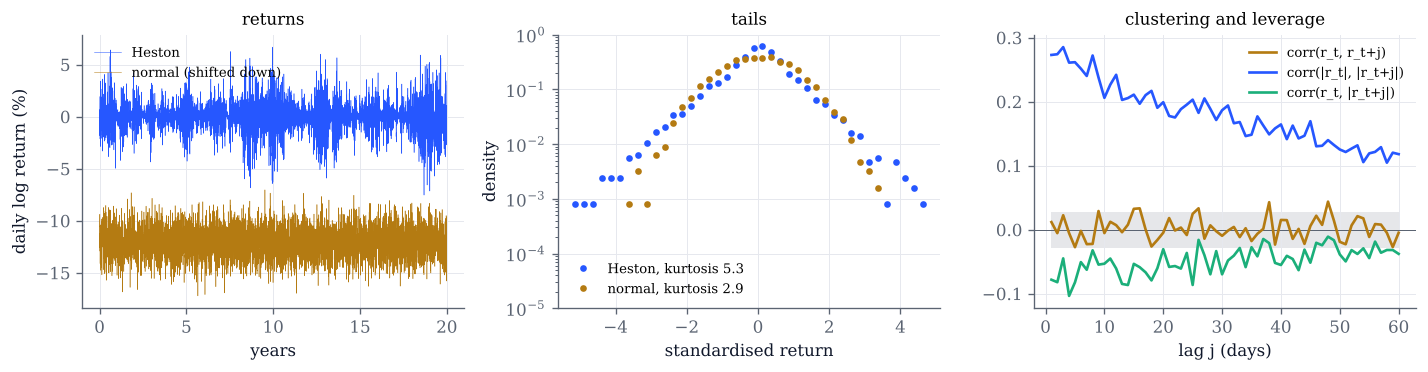

In [2]:
def stylised(xi=0.6, rho=-0.7, kappa=4.0, years=20, seed=15):
    n_days = 252 * years
    out = heston_paths(1.0, years, 0.07, 0.04, kappa, 0.04, xi, rho, 5 * n_days, 1, seed=seed, keep=True)
    r = np.diff(np.log(out["S_path"][0, ::5]))
    g = np.random.default_rng(seed + 1).normal(r.mean(), r.std(), size=r.size)
    fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
    axs[0].plot(np.arange(r.size) / 252, 100 * r, color=COBALT, lw=0.3, label="Heston")
    axs[0].plot(np.arange(r.size) / 252, 100 * g - 12, color=GOLD, lw=0.3, label="normal (shifted down)")
    axs[0].set(xlabel="years", ylabel="daily log return (%)", title="returns"); axs[0].legend(fontsize=8)
    bins = np.linspace(-7, 7, 57); mid = 0.5 * (bins[1:] + bins[:-1])
    for x, c, lab in ((r, COBALT, "Heston"), (g, GOLD, "normal")):
        hist, _ = np.histogram((x - x.mean()) / x.std(), bins=bins, density=True)
        axs[1].semilogy(mid[hist > 0], hist[hist > 0], "o", ms=3, color=c, label=f"{lab}, kurtosis {kurtosis(x):.1f}")
    axs[1].set(xlabel="standardised return", ylabel="density", ylim=(1e-5, 1), title="tails"); axs[1].legend(fontsize=8)
    lags = np.arange(1, 61)
    axs[2].axhline(0, color=GREY, lw=0.6)
    axs[2].fill_between(lags, -2 / np.sqrt(r.size), 2 / np.sqrt(r.size), color=GREY, alpha=0.15, lw=0)
    axs[2].plot(lags, autocorrelation(r, 60), color=GOLD, label="corr(r_t, r_t+j)")
    axs[2].plot(lags, autocorrelation(np.abs(r), 60), color=COBALT, label="corr(|r_t|, |r_t+j|)")
    axs[2].plot(lags, cross_correlation(r, np.abs(r), 60), color=GREEN, label="corr(r_t, |r_t+j|)")
    axs[2].set(xlabel="lag j (days)", title="clustering and leverage"); axs[2].legend(fontsize=8)
    fig.tight_layout(); plt.show()

stylised()

In [3]:
# Explore: xi = 0 gives Black-Scholes returns; rho = 0 removes the leverage effect but keeps tails and clustering.
interact(stylised,
         xi=FloatSlider(value=0.6, min=0.0, max=1.0, step=0.05, continuous_update=False, description="ξ"),
         rho=FloatSlider(value=-0.7, min=-0.95, max=0.95, step=0.05, continuous_update=False, description="ρ"),
         kappa=FloatSlider(value=4.0, min=0.5, max=20.0, step=0.5, continuous_update=False, description="κ"),
         years=IntSlider(value=20, min=5, max=40, step=5, continuous_update=False, description="years"),
         seed=IntSlider(value=15, min=0, max=50, continuous_update=False, description="seed"));

## 2. Computing implied volatility

The normalized call price $b(k,s)$ (equation 15.2) increases from $(1-e^k)^+$ to $1$ as the total volatility $s=\sigma\sqrt T$
goes from $0$ to $\infty$ (Proposition 15.2), so a price inside these bounds has exactly one implied volatility. The left panel
shows $s\mapsto b(k,s)$, a quoted price and the root; the dashed line is the upper bound $-2N^{-1}((1-c)/(1+e^k))$ of
Proposition 15.2(iv), which brackets the root for the solver of Remark 15.4.

The right panel shows why implied volatilities are noisy in the wings: if every price is off by one cent, the implied
volatility is off by about $0.01/\text{vega}$, and the vega is small far from the money and at short maturities.

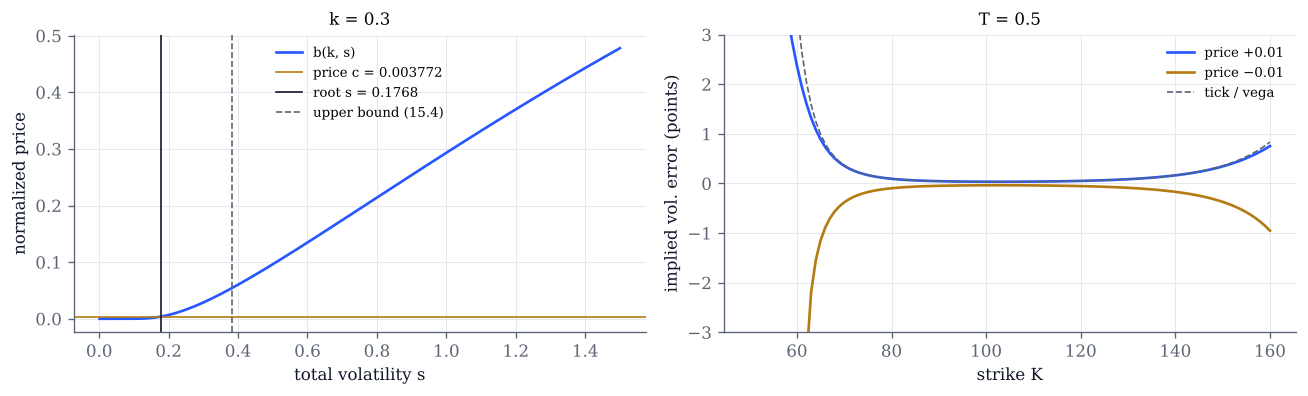

In [4]:
def implied(sigma=0.25, k=0.3, T=0.5, tick=0.01):
    s_true = sigma * np.sqrt(T)
    c = black_normalized(k, s_true)
    s_hat = implied_total_vol(c, k)
    s = np.linspace(1e-3, 1.5, 400)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
    ax.plot(s, black_normalized(k, s), color=COBALT, label="b(k, s)")
    ax.axhline(c, color=GOLD, lw=1, label=f"price c = {c:.4g}")
    ax.axvline(s_hat, color=INK, lw=1, label=f"root s = {s_hat:.4f}")
    ax.axvline(tehranchi_upper(c, k), color=GREY, ls="--", lw=1, label="upper bound (15.4)")
    ax.set(xlabel="total volatility s", ylabel="normalized price", title=f"k = {k}"); ax.legend(fontsize=8)
    K = np.linspace(50, 160, 111)
    F = S0 * np.exp(R * T)
    kk = np.log(K / F)
    C = S0 * black_normalized(kk, s_true)
    P = C - S0 + K * np.exp(-R * T)
    otm = np.where(K >= F, C, P)
    for sign, col in ((1, COBALT), (-1, GOLD)):
        noisy = np.maximum(otm + sign * tick, 1e-12)
        iv = np.where(K >= F, implied_vol(noisy, S0, K, T, R, kind="call"), implied_vol(noisy, S0, K, T, R, kind="put"))
        ax2.plot(K, 100 * (iv - sigma), color=col, label=f"price {'+' if sign > 0 else '−'}{tick}")
    vega = S0 * black_vega_normalized(kk, s_true) * np.sqrt(T)
    ax2.plot(K, 100 * tick / vega, color=GREY, ls="--", lw=1, label="tick / vega")
    ax2.set(xlabel="strike K", ylabel="implied vol. error (points)", ylim=(-3, 3), title=f"T = {T}")
    ax2.legend(fontsize=8); fig.tight_layout(); plt.show()

implied()

In [5]:
# Explore: move k far from 0, or T towards 0, and watch the implied volatility become ill-conditioned.
interact(implied,
         sigma=FloatSlider(value=0.25, min=0.05, max=1.0, step=0.01, continuous_update=False, description="σ"),
         k=FloatSlider(value=0.3, min=-1.5, max=1.5, step=0.05, continuous_update=False, description="k"),
         T=FloatSlider(value=0.5, min=0.02, max=3.0, step=0.02, continuous_update=False, description="T"),
         tick=FloatSlider(value=0.01, min=0.001, max=0.1, step=0.001, continuous_update=False, description="tick"));

## 3. Random variance makes a smile

If the total variance $V$ is random and independent of the shocks, $S_T=F\exp(\sqrt VZ-V/2)$, the call price is an average of
Black–Scholes prices (Proposition 15.9). Here $V$ is uniform on $[m(1-\delta),m(1+\delta)]$. The implied volatility is
symmetric in $k$, below $\sqrt{\mathbb E V}$ at the money, and above it for $|k|>\sqrt{\bar v+\bar v^2/4}$ (dotted lines),
where $\bar v=m(1+\delta)$ is the largest value of $V$.

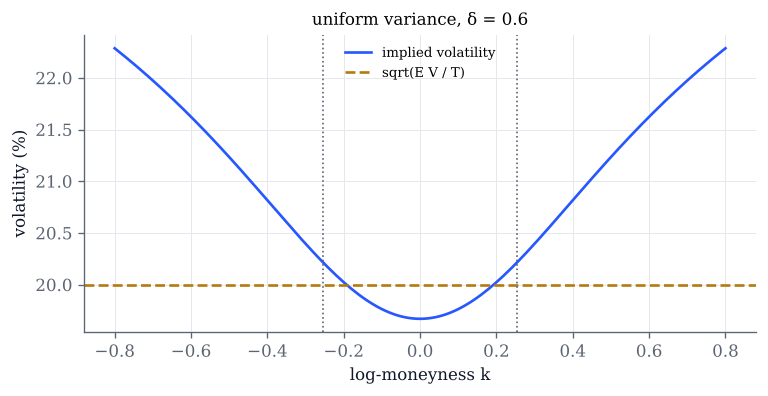

In [6]:
def mixing(sigma=0.2, T=1.0, delta=0.6):
    m = sigma**2 * T
    v = m * (1 + delta * np.linspace(-1, 1, 201))      # quadrature nodes for the uniform law
    k = np.linspace(-0.8, 0.8, 161)
    c = black_normalized(k[:, None], np.sqrt(v)[None, :]).mean(axis=1)
    iv = implied_total_vol(c, k) / np.sqrt(T)
    vbar = m * (1 + delta)
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.plot(k, 100 * iv, color=COBALT, label="implied volatility")
    ax.axhline(100 * sigma, color=GOLD, ls="--", label="sqrt(E V / T)")
    for x in (-1, 1):
        ax.axvline(x * np.sqrt(vbar + vbar**2 / 4), color=GREY, ls=":", lw=1)
    ax.set(xlabel="log-moneyness k", ylabel="volatility (%)", title=f"uniform variance, δ = {delta}")
    ax.legend(fontsize=8); fig.tight_layout(); plt.show()

mixing()

In [7]:
# Explore: delta = 0 is Black-Scholes, a flat smile; the smile deepens as the variance becomes more uncertain.
interact(mixing,
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ"),
         T=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"),
         delta=FloatSlider(value=0.6, min=0.0, max=0.99, step=0.01, continuous_update=False, description="δ"));

## 4. The Heston smile: Fourier inversion against Monte Carlo

Call prices from Lemma 15.10 with the characteristic function (15.12), converted to implied volatilities (lines), against
Monte Carlo prices of the full-truncation Euler scheme with the stock as control variate (dots, with 95% confidence
intervals turned into implied volatilities). The correlation $\rho$ tilts the smile, the volatility of variance $\xi$
curves it, and $v_0$ and $\theta$ set its short- and long-maturity levels.

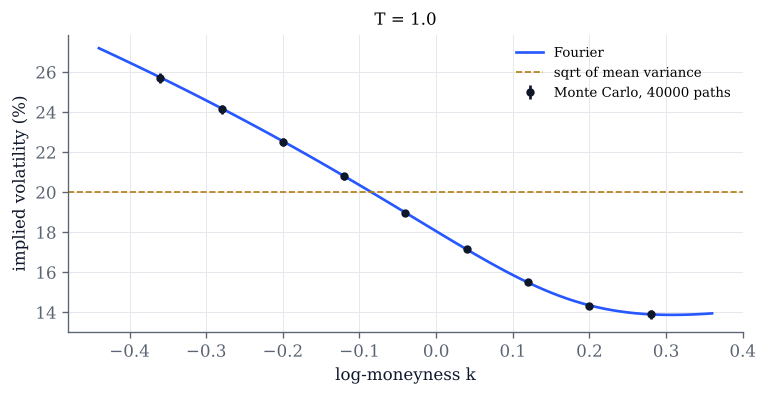

In [8]:
def heston_smile(rho=-0.7, xi=0.5, kappa=2.0, v0=0.04, theta=0.04, T=1.0, n_paths=40_000, seed=1):
    p = dict(v0=v0, kappa=kappa, theta=theta, xi=xi, rho=rho)
    F = S0 * np.exp(R * T)
    K = F * np.exp(np.linspace(-2.2, 1.8, 81) * np.sqrt(theta * T))
    iv = implied_vol(heston_call(S0, K, T, R, **p), S0, K, T, R)
    Kmc = F * np.exp(np.linspace(-1.8, 1.4, 9) * np.sqrt(theta * T))
    out = heston_paths(S0, T, R, n_steps=max(50, int(100 * T)), n_paths=n_paths, seed=seed, **p)
    price, se = mc_call_prices(out["S"], Kmc, F, np.exp(-R * T))
    mid = implied_vol(price, S0, Kmc, T, R)
    lo, hi = implied_vol(price - 1.96 * se, S0, Kmc, T, R), implied_vol(price + 1.96 * se, S0, Kmc, T, R)
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.plot(np.log(K / F), 100 * iv, color=COBALT, label="Fourier")
    ax.errorbar(np.log(Kmc / F), 100 * mid, yerr=100 * np.vstack([mid - lo, hi - mid]), fmt="o", ms=4, color=INK,
                capsize=0, label=f"Monte Carlo, {n_paths} paths")
    ax.axhline(100 * np.sqrt(heston_expected_variance(T, v0, kappa, theta)), color=GOLD, ls="--", lw=1,
               label="sqrt of mean variance")
    ax.set(xlabel="log-moneyness k", ylabel="implied volatility (%)", title=f"T = {T}")
    ax.legend(fontsize=8); fig.tight_layout(); plt.show()

heston_smile()

In [9]:
# Explore: rho = 0 gives the symmetric smile of Proposition 15.11(iii); rho < 0 an equity skew.
interact(heston_smile,
         rho=FloatSlider(value=-0.7, min=-0.95, max=0.95, step=0.05, continuous_update=False, description="ρ"),
         xi=FloatSlider(value=0.5, min=0.05, max=1.5, step=0.05, continuous_update=False, description="ξ"),
         kappa=FloatSlider(value=2.0, min=0.2, max=8.0, step=0.2, continuous_update=False, description="κ"),
         v0=FloatSlider(value=0.04, min=0.005, max=0.2, step=0.005, continuous_update=False, description="v0"),
         theta=FloatSlider(value=0.04, min=0.005, max=0.2, step=0.005, continuous_update=False, description="θ"),
         T=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, continuous_update=False, description="T"),
         n_paths=IntSlider(value=40_000, min=10_000, max=160_000, step=10_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 5. Static arbitrage checks on a parametric surface

An SSVI surface $w(k,T)=\frac{\theta_T}2\big(1+\rho\varphi k+\sqrt{(\varphi k+\rho)^2+1-\rho^2}\big)$ with
$\varphi=\eta\theta^{-\gamma}$ and $\theta_T=\sigma_0^2T$. For each maturity the code checks the butterfly condition $g\ge0$ of
Proposition 15.6(i) (left: the density $N'(d_-)g/\sqrt w$ of $\log(S_T/F_T)$, see (15.6), negative wherever $g<0$), and between consecutive
maturities the calendar condition $\partial_Tw\ge0$ of Proposition 15.6(ii) (right). A second correlation `rho_long`,
used for the longer maturities, lets you create calendar arbitrage; large `eta` creates butterfly arbitrage. Gatheral and
Jacquier's sufficient conditions are $\theta\varphi(1+|\rho|)<4$ and $\theta\varphi^2(1+|\rho|)\le4$.

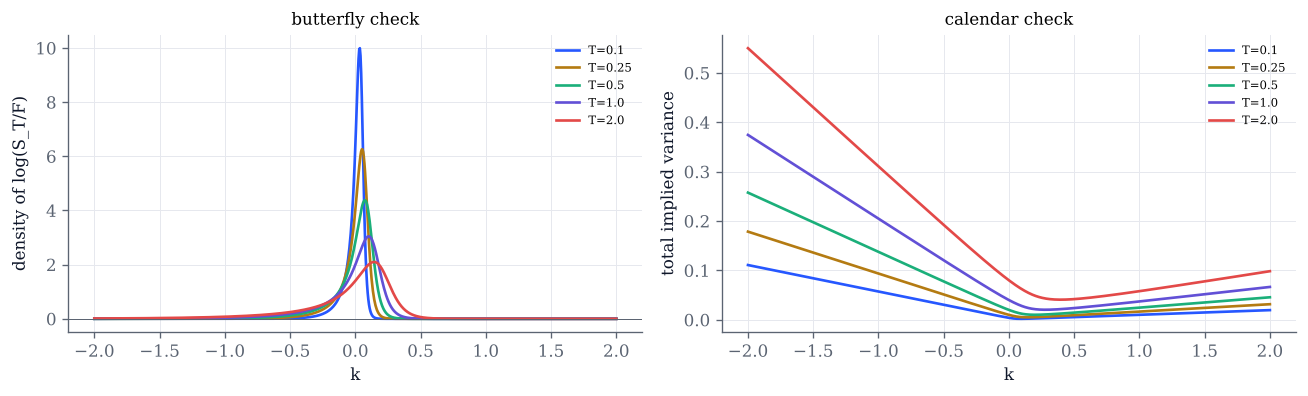

T=0.1: min g = +0.259; T=0.25: min g = +0.264; T=0.5: min g = +0.270; T=1.0: min g = +0.278; T=2.0: min g = +0.289
calendar arbitrage between maturities: none


In [10]:
def static_checks(sigma0=0.2, rho=-0.7, rho_long=-0.7, eta=1.0, gamma=0.5):
    k = np.linspace(-2, 2, 801)
    Ts = np.array([0.1, 0.25, 0.5, 1.0, 2.0])
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
    ws, report = [], []
    for i, T in enumerate(Ts):
        r = rho if T < 0.5 else rho_long
        w, wk, wkk, _ = ssvi(k, sigma0**2 * T, r, eta, gamma)
        g = butterfly_g(k, w, wk, wkk)
        ax.plot(k, density_from_w(k, w, wk, wkk), color=PALETTE[i % 5], label=f"T={T}")
        ax2.plot(k, w, color=PALETTE[i % 5], label=f"T={T}")
        ws.append(w)
        report.append(f"T={T}: min g = {g.min():+.3f}")
    ax.axhline(0, color=GREY, lw=0.6)
    ax.set(xlabel="k", ylabel="density of log(S_T/F)", title="butterfly check"); ax.legend(fontsize=7)
    ax2.set(xlabel="k", ylabel="total implied variance", title="calendar check"); ax2.legend(fontsize=7)
    fig.tight_layout(); plt.show()
    print("; ".join(report))
    cross = [f"{Ts[i]}->{Ts[i+1]}" for i in range(len(Ts) - 1) if np.any(ws[i + 1] < ws[i])]
    print("calendar arbitrage between maturities:", ", ".join(cross) if cross else "none")

static_checks()

In [11]:
# Explore: set rho_long far from rho to make the slices cross; raise eta to break the butterfly condition.
interact(static_checks,
         sigma0=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ0"),
         rho=FloatSlider(value=-0.7, min=-0.95, max=0.95, step=0.05, continuous_update=False, description="ρ"),
         rho_long=FloatSlider(value=-0.7, min=-0.95, max=0.95, step=0.05, continuous_update=False, description="ρ long"),
         eta=FloatSlider(value=1.0, min=0.1, max=6.0, step=0.1, continuous_update=False, description="η"),
         gamma=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, continuous_update=False, description="γ"));

## 6. Local volatility from Dupire's formula on a smooth surface

For the SSVI surface of Section 5 the derivatives of $w$ are explicit, and Dupire's formula in implied variance,
$\sigma(T,F_Te^k)^2=\partial_Tw/g$ (equation 15.11), gives the local volatility. Left: local volatility at three
times against implied volatility at $T$. Right: the local volatility model is simulated (Euler scheme for
$\log(S_t/F_t)$) and the implied volatilities of its Monte Carlo call prices are compared with the SSVI smile it was built
from (Remark 15.8).

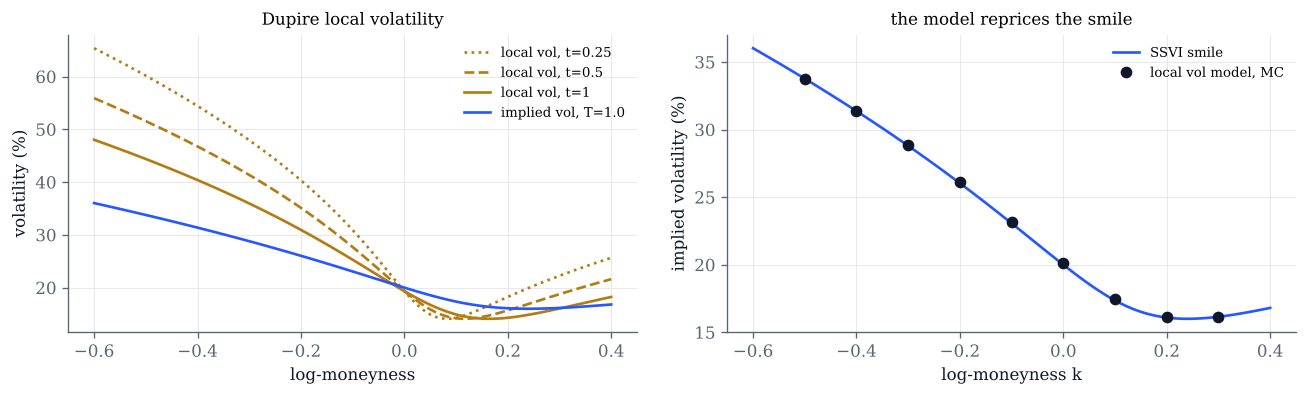

In [12]:
def dupire_ssvi(sigma0=0.2, rho=-0.6, eta=1.0, gamma=0.5, T=1.0, n_paths=40_000, seed=3):
    n = 100
    tg = np.linspace(0.0, T, n + 1)
    tl = tg.copy(); tl[0] = 0.5 * tg[1]
    kg = np.linspace(-2.0, 1.5, 351)
    lv = ssvi_local_vol_grid(tl, kg, sigma0**2, rho, eta, gamma)
    F = S0 * np.exp(R * T)
    k = np.linspace(-0.6, 0.4, 101)
    iv_ssvi = np.sqrt(ssvi(k, sigma0**2 * T, rho, eta, gamma)[0] / T)
    out = local_vol_paths(S0, T, R, 0.0, tg, kg, lv, n_paths, seed=seed)
    kmc = np.linspace(-0.5, 0.3, 9)
    price, se = mc_call_prices(out["S"], F * np.exp(kmc), F, np.exp(-R * T))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
    for frac, ls in ((0.25, ":"), (0.5, "--"), (1.0, "-")):
        j = int(frac * n)
        ax.plot(k, 100 * np.interp(k, kg, lv[j]), color=GOLD, ls=ls, label=f"local vol, t={tg[j]:.2g}")
    ax.plot(k, 100 * iv_ssvi, color=COBALT, label=f"implied vol, T={T}")
    ax.set(xlabel="log-moneyness", ylabel="volatility (%)", title="Dupire local volatility"); ax.legend(fontsize=8)
    ax2.plot(k, 100 * iv_ssvi, color=COBALT, label="SSVI smile")
    ax2.plot(kmc, 100 * implied_vol(price, S0, F * np.exp(kmc), T, R), "o", color=INK, label="local vol model, MC")
    ax2.set(xlabel="log-moneyness k", ylabel="implied volatility (%)", title="the model reprices the smile")
    ax2.legend(fontsize=8); fig.tight_layout(); plt.show()

dupire_ssvi()

In [13]:
# Explore: the local volatility skew is steeper than the implied one (about twice, near the money).
interact(dupire_ssvi,
         sigma0=FloatSlider(value=0.2, min=0.1, max=0.4, step=0.01, continuous_update=False, description="σ0"),
         rho=FloatSlider(value=-0.6, min=-0.9, max=0.9, step=0.05, continuous_update=False, description="ρ"),
         eta=FloatSlider(value=1.0, min=0.2, max=2.0, step=0.1, continuous_update=False, description="η"),
         gamma=FloatSlider(value=0.5, min=0.1, max=0.9, step=0.05, continuous_update=False, description="γ"),
         T=FloatSlider(value=1.0, min=0.25, max=2.0, step=0.25, continuous_update=False, description="T"),
         n_paths=IntSlider(value=40_000, min=10_000, max=160_000, step=10_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=3, min=0, max=50, continuous_update=False, description="seed"));

## 7. Same vanillas, different exotics

The Heston surface is turned into a local volatility by Dupire's formula in forward variables, with Fourier derivatives
of the call prices (no finite differences). Both models then price every vanilla option alike, but an up-and-out call
(strike 100, barrier monitored on the simulation grid) is priced differently: the barrier depends on the law of the whole
path, which the vanilla prices do not determine (Section 15.6).

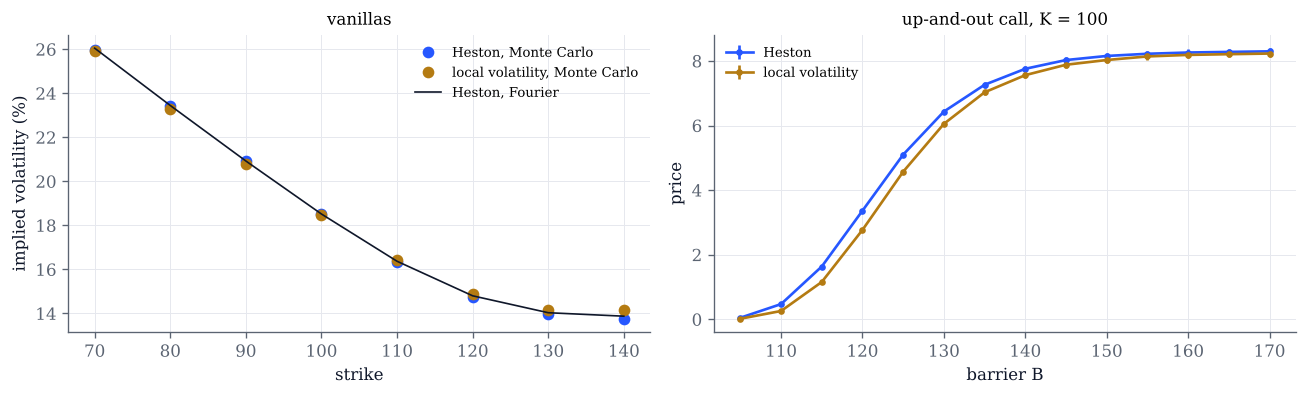

In [14]:
def exotics(rho=-0.7, xi=0.5, T=1.0, n_paths=40_000, seed=5):
    p = dict(v0=0.04, kappa=2.0, theta=0.04, xi=xi, rho=rho)
    n = int(200 * T)
    tg = np.linspace(0.0, T, n + 1)
    tl = tg.copy(); tl[0] = 0.5 * tg[1]
    kg = np.linspace(-1.5, 1.0, 251)
    lv = dupire_heston_grid(tl, kg, **p)
    lvp = local_vol_paths(S0, T, R, 0.0, tg, kg, lv, n_paths, seed=seed, running_max=True)
    hp = heston_paths(S0, T, R, n_steps=n, n_paths=n_paths, seed=seed + 1, running_max=True, **p)
    F = S0 * np.exp(R * T)
    K = np.arange(70.0, 141.0, 10.0)
    exact = implied_vol(heston_call(S0, K, T, R, **p), S0, K, T, R)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
    for paths, c, lab in ((hp, COBALT, "Heston"), (lvp, GOLD, "local volatility")):
        price, _ = mc_call_prices(paths["S"], K, F, np.exp(-R * T))
        ax.plot(K, 100 * implied_vol(price, S0, K, T, R), "o", color=c, label=f"{lab}, Monte Carlo")
    ax.plot(K, 100 * exact, color=INK, lw=1, label="Heston, Fourier")
    ax.set(xlabel="strike", ylabel="implied volatility (%)", title="vanillas"); ax.legend(fontsize=8)
    Bs = np.arange(105.0, 171.0, 5.0)
    for paths, c, lab in ((hp, COBALT, "Heston"), (lvp, GOLD, "local volatility")):
        v = np.array([up_and_out_call(paths["S"], paths["max"], 100.0, B, np.exp(-R * T)) for B in Bs])
        ax2.errorbar(Bs, v[:, 0], yerr=1.96 * v[:, 1], fmt="o-", ms=3, color=c, capsize=0, label=lab)
    ax2.set(xlabel="barrier B", ylabel="price", title="up-and-out call, K = 100"); ax2.legend(fontsize=8)
    fig.tight_layout(); plt.show()

exotics()

In [15]:
# Explore: with xi small the two models nearly coincide; the gap in barrier prices grows with the volatility of variance.
interact(exotics,
         rho=FloatSlider(value=-0.7, min=-0.9, max=0.9, step=0.1, continuous_update=False, description="ρ"),
         xi=FloatSlider(value=0.5, min=0.1, max=1.0, step=0.05, continuous_update=False, description="ξ"),
         T=FloatSlider(value=1.0, min=0.5, max=2.0, step=0.25, continuous_update=False, description="T"),
         n_paths=IntSlider(value=40_000, min=10_000, max=120_000, step=10_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=5, min=0, max=50, continuous_update=False, description="seed"));

## 8. Variance swaps and the VIX formula

The fair variance-swap strike is $\frac{2e^{rT}}T\int\text{OTM}(K)\,K^{-2}\,dK$ (Proposition 15.13). Here the option
prices are Heston prices on a grid of strikes with spacing $h$ between `K_min` and `K_max`, and the CBOE formula (15.14)
is applied to them. Its error splits into a discretization bias of about $h^2/(6TK_0^2)$ (upward) and a truncation
error from the missing wings (downward). The exact strike is $\theta+(v_0-\theta)(1-e^{-\kappa T})/(\kappa T)$
(Proposition 15.11(i)).

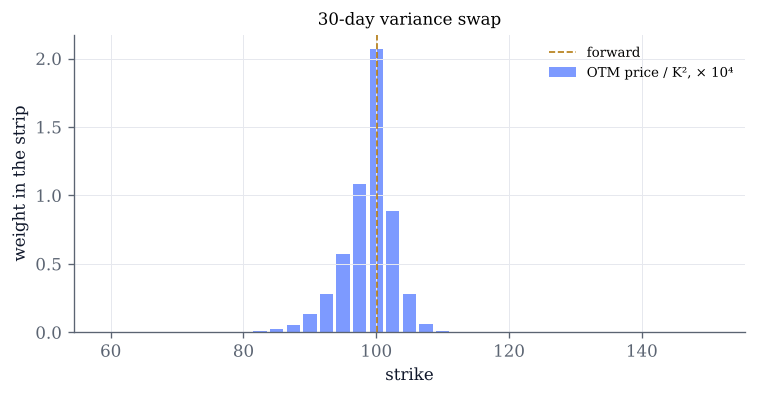

exact sqrt(K_var) = 17.764%, fine strip = 17.760%, CBOE formula = 18.119%; bias estimate h^2/(6 T K0^2) = 1.27e-03, actual error = +1.27e-03 (in variance)


In [16]:
def variance_swap(h=2.5, K_min=60.0, K_max=150.0, days=30, rho=-0.7, xi=0.5):
    p = dict(v0=0.03, kappa=2.0, theta=0.05, xi=xi, rho=rho)
    T = days / 365
    F = S0 * np.exp(R * T)
    exact = heston_expected_variance(T, p["v0"], p["kappa"], p["theta"])
    K = np.arange(K_min, K_max + 1e-9, h)
    C = heston_call(S0, K, T, R, **p)
    P = C - S0 + K * np.exp(-R * T)
    est = vix_sigma2(K, C, P, F, T, R)
    Kf = np.arange(1.0, 1500.0, 0.5)
    Cf = heston_call(S0, Kf, T, R, **p)
    strip = strip_variance(Kf, np.where(Kf < F, Cf - S0 + Kf * np.exp(-R * T), Cf), F, T, R)
    K0 = K[np.searchsorted(K, F, side="right") - 1]
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    otm = np.where(K < K0, P, C)
    ax.bar(K, otm / K**2 * 1e4, width=0.8 * h, color=COBALT, alpha=0.6, label="OTM price / K², × 10⁴")
    ax.axvline(F, color=GOLD, ls="--", lw=1, label="forward")
    ax.set(xlabel="strike", ylabel="weight in the strip", title=f"{days}-day variance swap"); ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()
    print(f"exact sqrt(K_var) = {100*np.sqrt(exact):.3f}%, fine strip = {100*np.sqrt(strip):.3f}%, "
          f"CBOE formula = {100*np.sqrt(est):.3f}%; bias estimate h^2/(6 T K0^2) = {h**2/(6*T*K0**2):.2e}, "
          f"actual error = {est - exact:+.2e} (in variance)")

variance_swap()

In [17]:
# Explore: halve h and the bias drops by four; narrow the strike range and the missing wings take over.
interact(variance_swap,
         h=FloatSlider(value=2.5, min=0.25, max=10.0, step=0.25, continuous_update=False, description="h"),
         K_min=FloatSlider(value=60.0, min=10.0, max=95.0, step=5.0, continuous_update=False, description="K min"),
         K_max=FloatSlider(value=150.0, min=105.0, max=400.0, step=5.0, continuous_update=False, description="K max"),
         days=IntSlider(value=30, min=7, max=365, step=1, continuous_update=False, description="days"),
         rho=FloatSlider(value=-0.7, min=-0.95, max=0.95, step=0.05, continuous_update=False, description="ρ"),
         xi=FloatSlider(value=0.5, min=0.05, max=1.0, step=0.05, continuous_update=False, description="ξ"));

## Things to try

* In Section 1, set $\rho=0$ and check that the leverage correlation vanishes while the kurtosis does not. Which parameter
  controls how long volatility clusters last?
* In Section 2, find the strikes at which a one-cent price error moves the implied volatility by more than one point,
  for $T=0.05$ and for $T=2$.
* In Section 4, compare the at-the-money implied volatility with the dashed line (the square root of the mean
  variance) for $\rho=0$ and for $\rho=-0.9$. Is the at-the-money volatility always below it?
* In Section 5, find the smallest `eta` that produces butterfly arbitrage for $\rho=-0.7$, and compare with the two
  conditions of Gatheral and Jacquier.
* In Section 7, at which barrier levels do the two models disagree most, relative to the price?
* In Section 8, with a fine grid, how wide must the strike range be for the truncation error to be below one basis
  point of variance at 30 days? At one year?